# LỜI GIẢI ĐỀ 1 - KHAI PHÁ DỮ LIỆU WEB

Notebook giải đầy đủ hai câu bằng dữ liệu offline, đường dẫn tương đối và mã hóa UTF-8.

> **Lưu ý dữ liệu:** Đề ghi dữ liệu review khách sạn, nhưng `reviews_raw.csv` hiện chứa review nhà hàng. Lời giải xử lý đúng dữ liệu thực tế.

## Cơ sở kiến thức sử dụng

- **Chương 1:** quy trình khai phá dữ liệu gồm làm sạch, chuyển đổi, khai phá và biểu diễn kết quả.
- **Chương 2:** HTML là dữ liệu bán cấu trúc; dùng BeautifulSoup với parser `html5lib` để tìm các thẻ theo CSS selector.
- **Chương 3:** tiền xử lý theo chuỗi hợp lý: chữ thường → bỏ HTML/URL/số → đổi emoji và chuẩn hóa từ → bỏ dấu câu → tách từ → bỏ stop word → thống kê và trực quan hóa.

Mỗi bước được lưu riêng để dễ kiểm tra và chạy lại.

In [10]:
# ============================================================
# KHỞI TẠO THƯ VIỆN VÀ ĐƯỜNG DẪN
# Tham chiếu slide: Chương 2; Ví dụ 3.4b và 3.10 (Chương 3)
# ============================================================
# Path quản lý đường dẫn theo hướng đối tượng; Counter dùng để đếm token.
from pathlib import Path
from collections import Counter
import re
import unicodedata

import pandas as pd
from bs4 import BeautifulSoup
from underthesea import word_tokenize
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from IPython.display import display

# Lấy thư mục đang mở trong VS Code; mọi đường dẫn phía dưới đều là tương đối.
ROOT = Path.cwd()
DATA_CH2 = ROOT / "Data" / "Chuong2" / "pages"
DATA_CH3 = ROOT / "Data" / "Chuong3"
CAU1 = ROOT / "Cau1"
CAU2 = ROOT / "Cau2"
# Tạo thư mục kết quả nếu chưa tồn tại; không sửa dữ liệu gốc trong Data.
CAU1.mkdir(exist_ok=True)
CAU2.mkdir(exist_ok=True)

print("Thư mục làm việc:", ROOT)

# 📌 CÁCH THEO SLIDE (Ví dụ 3.4b) – chỉ tham khảo, không chạy:
# import os
# path = os.path.dirname(__file__)
# Path được dùng ở đây thay cho os.path vì ghép đường dẫn bằng toán tử / rõ ràng hơn
# và hoạt động trên cả Windows, macOS, Linux. Counter tương đương bước thống kê
# tần suất bằng nltk trong Ví dụ 3.10, nhưng gọn hơn cho bài toán unigram này.

Thư mục làm việc: d:\Nam4\KPW_4\GiuaKi\LoiGiai\4_DoHuuHau


## Câu 1a - Đọc HTML và in tên 4 sản phẩm

`select(".product-card")` lấy từng khối sản phẩm; bên trong mỗi khối, `select_one(".product-name")` lấy đúng tên. `html5lib` có khả năng sửa HTML chưa hoàn chỉnh như nội dung Chương 2.

In [11]:
# ============================================================
# CÂU 1a – ĐỌC HTML VÀ IN TÊN 4 SẢN PHẨM
# Tham chiếu slide: Ví dụ 2.5a (Chương 2)
# ============================================================
# Đề cho dữ liệu offline nên đọc trực tiếp file, không gọi requests.get().
page1 = (DATA_CH2 / "page1.html").read_text(encoding="utf-8")
# html5lib có khả năng hoàn thiện cấu trúc HTML trước khi bóc tách.
soup = BeautifulSoup(page1, "html5lib")

# CSS selector lấy từng card, sau đó lấy đúng tên nằm trong card đó.
for card in soup.select(".product-card"):
    print(card.select_one(".product-name").get_text(strip=True))

# 📌 CÁCH THEO SLIDE (Ví dụ 2.5a) – tương đương, không chạy:
# product_names = soup.find_all("h3", class_="product-name")
# for name in product_names:
#     print(name.text.strip())
# select()/select_one() là cú pháp CSS tương đương find_all()/find().

Laptop Alpha 14
Laptop Beta Air
Laptop Gamma Book
Laptop Delta Mini


## Câu 1b - Bóc tách cả hai trang

Hàm `text_or_empty` giúp trường khuyến mại có thể thiếu mà chương trình không lỗi. Mỗi sản phẩm trở thành một dòng dữ liệu có cấu trúc.

In [12]:
# ============================================================
# CÂU 1b – BÓC TÁCH 8 SẢN PHẨM VÀ LƯU CSV
# Tham chiếu slide: Ví dụ 2.5a (Chương 2)
# ============================================================
# Trả chuỗi rỗng nếu card không có thẻ khuyến mại, tránh lỗi None.get_text().
def text_or_empty(card, selector):
    tag = card.select_one(selector)
    return tag.get_text(" ", strip=True) if tag else ""

# Mỗi card được xử lý độc lập để các trường luôn thuộc cùng một sản phẩm.
products = []
for file_name in ["page1.html", "page2.html"]:
    html = (DATA_CH2 / file_name).read_text(encoding="utf-8")
    soup = BeautifulSoup(html, "html5lib")
    for card in soup.select("article.product-card"):
        products.append({
            "ten_sp": text_or_empty(card, ".product-name"),
            "gia_goc": text_or_empty(card, ".list-price"),
            "gia_ban": text_or_empty(card, ".sale-price"),
            "khuyen_mai": text_or_empty(card, ".promotion"),
        })

raw_products = pd.DataFrame(products)
raw_path = CAU1 / "san_pham_tho.csv"
# index=False không ghi thêm cột chỉ số; UTF-8 đáp ứng yêu cầu đề.
raw_products.to_csv(raw_path, index=False, encoding="utf-8")

assert len(raw_products) == 8
display(raw_products)

# 📌 CÁCH THEO SLIDE (Ví dụ 2.5a) – chỉ tham khảo, không chạy:
# TenSP = soup.find_all("h3", class_="product-name")
# GiaGoc = soup.find_all("span", class_="list-price")
# GiaBan = soup.find_all("span", class_="sale-price")
# KhuyenMai = soup.find_all("p", class_="promotion")
# for i in range(len(TenSP)): ...
#
# ⚠️ VÌ SAO BÀI NÀY KHÁC SLIDE:
# Có 8 sản phẩm nhưng chỉ 7 thẻ promotion. Nếu lấy từng danh sách riêng rồi ghép
# theo chỉ số i, từ sản phẩm thiếu promotion trở đi dữ liệu sẽ bị lệch dòng. Duyệt
# từng card giúp giữ đúng quan hệ giữa tên, giá và khuyến mại.

,ten_sp,gia_goc,gia_ban,khuyen_mai
0,Laptop Alpha 14,21.990.000 đ,18.990.000 đ,Tặng chuột không dây
1,Laptop Beta Air,17.500.000 đ,16.990.000 đ,Giảm thêm 300.000 đ qua mã WEB
2,Laptop Gamma Book,25.000.000 đ,21.250.000 đ,Trả góp 0 phần trăm
3,Laptop Delta Mini,14.200.000 đ,14.200.000 đ,
4,Laptop Epsilon Pro,32.490.000 đ,27.990.000 đ,Tặng balo và chuột
5,Laptop Zeta Office,19.900.000 đ,18.500.000 đ,Bảo hành 24 tháng
6,Laptop Eta Gaming,35.750.000 đ,28.600.000 đ,Tặng tai nghe gaming
7,Laptop Theta Student,12.800.000 đ,11.990.000 đ,Giảm giá sinh viên


## Câu 1c - Làm sạch dữ liệu sản phẩm

Đề yêu cầu xử lý **từ** `san_pham_tho.csv`, vì vậy tệp của ý 1b được đọc lại thay vì dùng biến trong bộ nhớ. `keep_default_na=False` giữ ô khuyến mại rỗng dưới dạng chuỗi rỗng. Giá được chuyển sang số nguyên và tỷ lệ giảm được làm tròn 2 chữ số.

In [13]:
# ============================================================
# CÂU 1c – LÀM SẠCH GIÁ VÀ TÍNH TỶ LỆ GIẢM
# Tham chiếu slide: Biểu thức chính quy Chương 2; Ví dụ 3.2c (Chương 3)
# ============================================================
# Đọc lại đúng tệp đầu ra của ý 1b theo yêu cầu đề
# Đọc lại file của ý 1b; giữ ô rỗng là "" thay vì tự đổi thành NaN.
raw_products = pd.read_csv(raw_path, encoding="utf-8", keep_default_na=False)

def parse_vnd(value):
    # \D nghĩa là "không phải chữ số": loại dấu chấm, khoảng trắng và chữ đ.
    digits = re.sub(r"\D", "", str(value))
    return int(digits) if digits else 0

clean_products = raw_products.copy()
clean_products["gia_goc_vnd"] = clean_products["gia_goc"].apply(parse_vnd)
clean_products["gia_ban_vnd"] = clean_products["gia_ban"].apply(parse_vnd)
clean_products["khuyen_mai"] = clean_products["khuyen_mai"].replace(
    "", "Không có khuyến mại"
)
clean_products["ty_le_giam"] = (
    (clean_products["gia_goc_vnd"] - clean_products["gia_ban_vnd"])
    / clean_products["gia_goc_vnd"] * 100
).round(2)

clean_products = clean_products[[
    "ten_sp", "gia_goc_vnd", "gia_ban_vnd", "khuyen_mai", "ty_le_giam"
]]
clean_path = CAU1 / "san_pham_sach.csv"
clean_products.to_csv(clean_path, index=False, encoding="utf-8")
display(clean_products)

# 📌 LIÊN HỆ SLIDE (Ví dụ 3.2c):
# Slide dùng \d+ để tìm/xóa chữ số trong văn bản; bài này dùng mẫu ngược lại
# \D để xóa mọi ký tự không phải số và giữ lại số nguyên VND.

,ten_sp,gia_goc_vnd,gia_ban_vnd,khuyen_mai,ty_le_giam
0,Laptop Alpha 14,21990000,18990000,Tặng chuột không dây,13.64
1,Laptop Beta Air,17500000,16990000,Giảm thêm 300.000 đ qua mã WEB,2.91
2,Laptop Gamma Book,25000000,21250000,Trả góp 0 phần trăm,15.00
3,Laptop Delta Mini,14200000,14200000,Không có khuyến mại,0.00
4,Laptop Epsilon Pro,32490000,27990000,Tặng balo và chuột,13.85
5,Laptop Zeta Office,19900000,18500000,Bảo hành 24 tháng,7.04
6,Laptop Eta Gaming,35750000,28600000,Tặng tai nghe gaming,20.00
7,Laptop Theta Student,12800000,11990000,Giảm giá sinh viên,6.33


## Câu 2a - Tiền xử lý bước 1

**Thứ tự thực hiện:**

1. Xóa thẻ HTML trước để các bước regex sau không làm biến dạng dấu `<`, `>`.
2. Chuyển chữ thường; bước này đặt trước hay sau bước 1 đều cho cùng kết quả với dữ liệu hiện tại.
3. Xóa URL trước khi xóa chữ số vì URL có thể chứa số, tránh để lại phần URL bị vỡ.
4. Xóa chữ số còn lại.
5. Gộp nhiều khoảng trắng liên tiếp thành một khoảng trắng.

Emoji, emoticon và dấu câu vẫn được giữ lại cho bước 2.

In [14]:
# ============================================================
# CÂU 2a – XÓA HTML, URL, CHỮ SỐ VÀ CHUẨN HÓA KHOẢNG TRẮNG
# Tham chiếu slide: Ví dụ 3.1, 3.2c, 3.2d (Chương 3)
# ============================================================
reviews = pd.read_csv(DATA_CH3 / "reviews_raw.csv", encoding="utf-8")

def clean_step1(text):
    # get_text(" ") bỏ thẻ nhưng chèn khoảng trắng giữa các vùng văn bản.
    text = BeautifulSoup(str(text), "html.parser").get_text(" ")
    # Ví dụ 3.1: đưa toàn bộ văn bản về chữ thường.
    text = text.lower()
    # Xóa URL trước chữ số để URL có số không bị vỡ thành phần rác.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    # split rồi join gộp mọi dãy khoảng trắng về đúng một khoảng trắng.
    return " ".join(text.split())

step1 = reviews[["id"]].copy()
step1["review_buoc1"] = reviews["review"].apply(clean_step1)
step1.to_csv(CAU2 / "buoc1.csv", index=False, encoding="utf-8")
display(step1)

# 📌 CÁCH THEO SLIDE (Ví dụ 3.2d) – chỉ tham khảo, không chạy:
# soup = BeautifulSoup(html, "html.parser")
# for data in soup(["style", "script"]):
#     data.decompose()
# text = " ".join(soup.stripped_strings)
# Dữ liệu đề không có thẻ script/style nên get_text(" ") cho cùng mục đích, gọn hơn.

,id,review_buoc1
0,NH01,quan sao!!! nhân viên phục vụ rất nhanh 😍. xem...
1,NH02,"món bún ngon, nước dùng đậm đà :) nhưng chỗ ng..."
2,NH03,"đồ ăn ok, giá . đ cho khách là hợp lý."
3,NH04,tôi đặt bàn qua xác nhận rất nhanh!!!
4,NH05,"nhân viên nhiệt tình, nhưng món lên hơi lâu..."
5,NH06,"quán gần nhà, vị trí tiện, sẽ quay lại :d"
6,NH07,"món ăn nguội, phục vụ chậm phút, tôi thất vọng 😒"
7,NH08,"không gian sạch sẽ, nhạc nhẹ và dễ chịu!"
8,NH09,"pvu tốt nhưng tolet chưa sạch, tôi kg hài lòng."
9,NH10,"thực đơn đa dạng, món mới ngon, đáng tiền %."


## Câu 2b - Đổi emoji, chuẩn hóa từ và bỏ dấu câu

Đề yêu cầu xử lý **từ** `buoc1.csv`, nên tệp được đọc lại ở đầu ý. Emoji/emoticon được thay trước khi xóa dấu câu. Dấu gạch nối giữa hai ký tự được bỏ để `check-in` thành `checkin`; từ này chỉ được thay tiếp nếu thực sự có trong từ điển đề bài. Từ điển được khớp chính xác theo nguyên từ, vì `quan` là dạng sai cần sửa còn `quán` là từ viết đúng.

In [15]:
# ============================================================
# CÂU 2b – ĐỔI EMOJI, CHUẨN HÓA TỪ VÀ XÓA DẤU CÂU
# Tham chiếu slide: Ví dụ 3.2a, 3.3, 3.6 (Chương 3)
# ============================================================
# Đọc lại đúng tệp đầu ra của ý 2a
step1 = pd.read_csv(CAU2 / "buoc1.csv", encoding="utf-8", keep_default_na=False)

emoji_map = pd.read_csv(DATA_CH3 / "emoji_map.csv", encoding="utf-8")
word_map = pd.read_csv(DATA_CH3 / "tu_dien_chuan_hoa.csv", encoding="utf-8")

# File map của đề thay cho từ điển emoji thuộc thư viện emot trong Ví dụ 3.3.
emoji_dict = {
    str(symbol).lower(): meaning
    for symbol, meaning in zip(emoji_map["ky_hieu"], emoji_map["van_ban"])
}
normalize_dict = dict(zip(word_map["tu_goc"], word_map["tu_chuan"]))

def replace_whole_word(text, old, new):
    pattern = rf"(?<!\w){re.escape(old)}(?!\w)"
    return re.sub(pattern, new, text)

def clean_step2(text):
    # Duyệt ký hiệu dài trước để tránh thay một phần emoticon ngắn hơn
    for symbol, meaning in sorted(emoji_dict.items(), key=lambda item: -len(item[0])):
        text = text.replace(symbol, f" {meaning} ")

    # Ví dụ: check-in -> checkin trước khi tra từ điển
    # (?<=\w) và (?=\w) kiểm tra hai phía là ký tự từ nhưng không lấy chúng.
    # Nhờ đó chỉ dấu gạch nối nằm giữa từ bị xóa: check-in -> checkin.
    text = re.sub(r"(?<=\w)-(?=\w)", "", text)
    # Thay nguyên từ theo ranh giới từ, tránh thay nhầm một phần từ khác.
    for old, new in sorted(normalize_dict.items(), key=lambda item: -len(item[0])):
        text = replace_whole_word(text, old, new)

    # Thay dấu câu bằng khoảng trắng để hai từ hai bên không bị dính vào nhau.
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return " ".join(text.split())

step2 = step1[["id"]].copy()
step2["review_buoc2"] = step1["review_buoc1"].apply(clean_step2)
step2.to_csv(CAU2 / "buoc2.csv", index=False, encoding="utf-8")
display(step2)

# 📌 CÁCH THEO SLIDE (Ví dụ 3.3 và 3.6) – chỉ tham khảo, không chạy:
# for symbol in EMOTICONS_EMO:
#     text = text.replace(symbol, EMOTICONS_EMO[symbol])
# words = text.split()
# words = [lookup_dict.get(word, word) for word in words]
#
# ⚠️ VÌ SAO BÀI NÀY KHÁC SLIDE:
# 1) Đề đã cho emoji_map.csv nên không cần thư viện emot.
# 2) split() trước khi bỏ dấu câu làm "ok," không khớp khóa "ok"; regex ranh giới
#    từ xử lý được trường hợp này.
# 3) Slide thay dấu câu bằng chuỗi rỗng có thể làm dính chữ, ví dụ
#    "forward,python" -> "forwardpython". Bài này thay bằng khoảng trắng.

,id,review_buoc2
0,NH01,nha hang sao nhân viên phục vụ rất nhanh yeu_t...
1,NH02,món bún ngon nước dùng đậm đà vui_ve nhưng chỗ...
2,NH03,đồ ăn tot giá đ cho khách là hợp lý
3,NH04,tôi đặt bàn qua xác nhận rất nhanh
4,NH05,nhân viên nhiệt tình nhưng món lên hơi lâu
5,NH06,quán gần nhà vị trí tiện sẽ quay lại cuoi_lon
6,NH07,món ăn nguội phục vụ chậm phút tôi thất vọng k...
7,NH08,không gian sạch sẽ nhạc nhẹ và dễ chịu
8,NH09,phuc vu tốt nhưng toilet chưa sạch tôi khong h...
9,NH10,thực đơn đa dạng món mới ngon đáng tiền


## Câu 2c - Tách từ tiếng Việt và loại stop word

Đề yêu cầu xử lý **từ** `buoc2.csv`. `underthesea.word_tokenize(..., format="text")` được dùng để tách từ tiếng Việt. Do `stopwords.txt` được cung cấp hoàn toàn không dấu, token được bỏ dấu bằng thư viện chuẩn `unicodedata` trước khi đối chiếu.

**Giới hạn:** phép bỏ dấu có thể làm các từ khác nghĩa trùng nhau, chẳng hạn `chỗ` và `cho` đều thành `cho`, hoặc `hơi` và `hỏi` đều thành `hoi`. Với dữ liệu hiện tại, `chỗ` bị loại do va chạm với stop word `cho`; đây là giới hạn của từ điển đầu vào và được giải trình rõ, không chỉnh tay kết quả.

In [16]:
# ============================================================
# CÂU 2c – TÁCH TỪ TIẾNG VIỆT VÀ LOẠI STOP WORD
# Tham chiếu slide: Ví dụ 3.4b và 3.8b (Chương 3)
# ============================================================
# Đọc lại đúng tệp đầu ra của ý 2b
step2 = pd.read_csv(CAU2 / "buoc2.csv", encoding="utf-8", keep_default_na=False)

# Dùng set thay list như slide để phép kiểm tra "in" có thời gian trung bình O(1).
stop_words = {
    line.strip().lower()
    for line in (DATA_CH3 / "stopwords.txt").read_text(encoding="utf-8").splitlines()
    if line.strip()
}

def remove_accents(text):
    """Chuyển tiếng Việt có dấu về không dấu để so với stopwords.txt."""
    # NFD tách ký tự có dấu thành chữ cái gốc và dấu kết hợp.
    text = unicodedata.normalize("NFD", text)
    # Nhóm Unicode Mn là các dấu kết hợp; loại nhóm này để thu được chữ không dấu.
    text = "".join(char for char in text if unicodedata.category(char) != "Mn")
    # Chữ đ không tách dấu theo NFD nên phải đổi riêng.
    return text.replace("đ", "d").replace("Đ", "D")

def tokenize_and_remove_stopwords(text):
    # Giống Ví dụ 3.8b: từ ghép tiếng Việt được nối bằng dấu gạch dưới.
    tokens = word_tokenize(text, format="text").split()
    remaining = [
        token for token in tokens
        if remove_accents(token.lower()) not in stop_words
    ]
    return " ".join(remaining)

step3 = step2[["id"]].copy()
step3["tokens"] = step2["review_buoc2"].apply(tokenize_and_remove_stopwords)
step3.to_csv(CAU2 / "buoc3.csv", index=False, encoding="utf-8")
display(step3)

# 📌 CÁCH THEO SLIDE (Ví dụ 3.4b) – chỉ tham khảo, không chạy:
# List_StopWords = file.read().split("\n")
# text_pre = " ".join(word for word in text.split() if word not in List_StopWords)
# Bài này phải tách từ bằng underthesea trước theo yêu cầu đề; đồng thời so bản
# không dấu vì stopwords.txt được cung cấp ở dạng không dấu. unicodedata là
# thư viện chuẩn của Python, không cần cài thêm khi thi offline.

,id,tokens
0,NH01,nha hang sao nhân_viên phục_vụ nhanh yeu_thich...
1,NH02,món bún ngon nước dùng đậm_đà vui_ve ngồi chật...
2,NH03,đồ_ăn tot giá đ khách hợp_lý
3,NH04,đặt bàn xác_nhận nhanh
4,NH05,nhân_viên nhiệt_tình món lên lâu
5,NH06,quán gần nhà vị_trí tiện quay cuoi_lon
6,NH07,món ăn nguội phục_vụ chậm phút thất_vọng khong...
7,NH08,không_gian sạch_sẽ nhạc_nhẹ dễ_chịu
8,NH09,phuc vu tốt toilet sạch khong hài_lòng
9,NH10,thực_đơn đa_dạng món mới ngon_đáng tiền


**Giải trình kết quả tách từ:** từ điển chuẩn hóa có một số giá trị không dấu, nên `underthesea` có thể xử lý khác với cụm có dấu. Ví dụ `phuc vu` (từ `pvu`) có thể tách thành hai token `phuc`, `vu`, trong khi `phục vụ` được ghép thành `phục_vụ`. Vì vậy các biến thể này được đếm riêng. Chương trình giữ nguyên kết quả của thư viện theo đúng đề, không gộp hoặc sửa token thủ công.

## Câu 2d - Thống kê 10 unigram phổ biến nhất

Đề yêu cầu thống kê **từ** `buoc3.csv`, nên tệp được đọc lại ở đầu ý. `Counter` đếm toàn bộ token; khóa `(-tần_suất, token)` bảo đảm giảm dần theo tần suất và tăng dần theo token khi bằng nhau.

In [17]:
# ============================================================
# CÂU 2d – THỐNG KÊ VÀ SẮP XẾP TOP 10 UNIGRAM
# Tham chiếu slide: Ví dụ 3.10 (Chương 3)
# ============================================================
# Đọc lại đúng tệp đầu ra của ý 2c
step3 = pd.read_csv(CAU2 / "buoc3.csv", encoding="utf-8", keep_default_na=False)

all_tokens = " ".join(step3["tokens"]).split()
# Counter tạo ánh xạ token -> số lần xuất hiện.
frequency = Counter(all_tokens)

# -item[1]: tần suất giảm dần; item[0]: token tăng dần khi bằng tần suất.
sorted_frequency = sorted(frequency.items(), key=lambda item: (-item[1], item[0]))
top10 = pd.DataFrame(sorted_frequency[:10], columns=["token", "tan_suat"])
top10.to_csv(CAU2 / "tan_suat_top10.csv", index=False, encoding="utf-8")
display(top10)

# 📌 CÁCH THEO SLIDE (Ví dụ 3.10) – chỉ tham khảo, không chạy:
# import nltk
# freq = nltk.FreqDist(all_tokens)
# top10_slide = freq.most_common(10)
# Slide chỉ cho biết dùng nltk và hiển thị output; FreqDist là cách phổ biến
# cho dạng kết quả này, không khẳng định đây là nguyên văn code của giảng viên.
#
# ⚠️ VÌ SAO BÀI NÀY KHÁC SLIDE:
# most_common() bảo đảm giảm dần theo tần suất nhưng không bảo đảm tăng dần theo
# token khi bằng nhau. Đề yêu cầu cả hai tiêu chí nên phải dùng sorted với khóa kép.

,token,tan_suat
0,món,4
1,nhanh,2
2,nhân_viên,2
3,phục_vụ,2
4,thực_đơn,2
5,bàn,1
6,bún,1
7,chậm,1
8,chật,1
9,cuoi_lon,1


## Câu 2e - Biểu đồ, word cloud và nhận xét

Biểu đồ cột ngang hỗ trợ so sánh tần suất chính xác; word cloud giúp nhìn nhanh các token nổi bật. Nhận xét chỉ mô tả thống kê, không suy diễn cảm xúc.

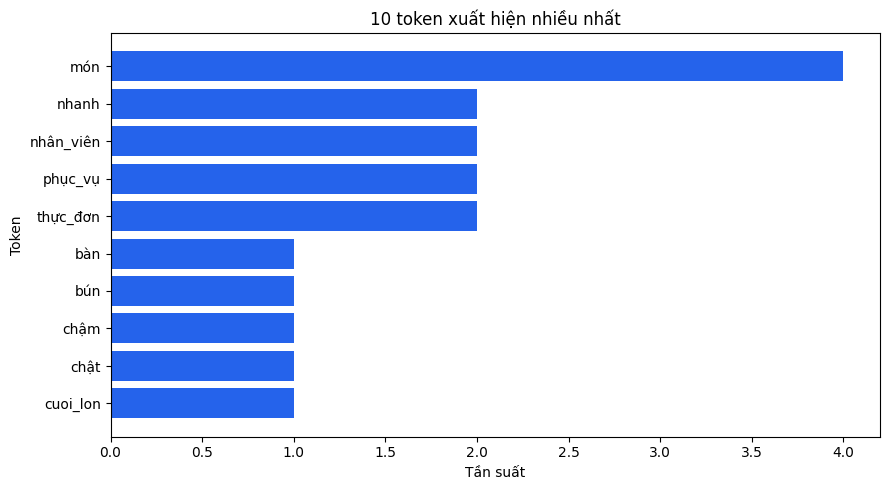

1. Token 'món' xuất hiện nhiều nhất (4 lần), cho thấy món ăn là nội dung được nhắc đến nhiều nhất trong các review.
2. 'nhân_viên' và 'phục_vụ' cùng xuất hiện 2 và 2 lần; việc phục vụ là một chủ đề được đề cập thường xuyên.
3. 'thực_đơn' xuất hiện 2 lần và 'nhanh' xuất hiện 2 lần, liên quan đến món ăn và tốc độ phục vụ.
Ghi chú: dạng không dấu 'phuc vu' được tách thành 'phuc' (1 lần) và 'vu' (1 lần), nên được đếm riêng với token 'phục_vụ'.


In [18]:
# ============================================================
# CÂU 2e – BIỂU ĐỒ, WORD CLOUD VÀ NHẬN XÉT
# Tham chiếu slide: Ví dụ 3.10 (Chương 3)
# ============================================================
# Đảo top 10 để token có tần suất cao nhất nằm trên cùng biểu đồ ngang.
plot_data = top10.iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(plot_data["token"], plot_data["tan_suat"], color="#2563eb")
plt.xlabel("Tần suất")
plt.ylabel("Token")
plt.title("10 token xuất hiện nhiều nhất")
plt.tight_layout()
plt.savefig(CAU2 / "bieu_do_top10.png", dpi=150)
plt.show()

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    collocations=False,
# Dùng lại bảng tần suất của ý 2d, không tách từ hay đếm lại dữ liệu.
).generate_from_frequencies(frequency)
wordcloud.to_file(str(CAU2 / "wordcloud.png"))

# Lấy số liệu trực tiếp từ kết quả ý 2d; báo rõ nếu tokenizer làm thay đổi
# các token dùng trong phần nhận xét.
frequency_top10 = dict(zip(top10["token"], top10["tan_suat"]))
assert top10.iloc[0]["token"] == "món", (
    "Token đứng đầu đã thay đổi; cần viết lại nhận xét theo kết quả mới."
)
for token in ["nhân_viên", "phục_vụ", "thực_đơn"]:
    assert token in frequency_top10, (
        f"Token '{token}' không còn trong top 10; cần viết lại nhận xét."
    )

comments = [
    f"1. Token 'món' xuất hiện nhiều nhất ({frequency_top10['món']} lần), "
    "cho thấy món ăn là nội dung được nhắc đến nhiều nhất trong các review.",
    f"2. 'nhân_viên' và 'phục_vụ' cùng xuất hiện "
    f"{frequency_top10['nhân_viên']} và {frequency_top10['phục_vụ']} lần; "
    "việc phục vụ là một chủ đề được đề cập thường xuyên.",
    f"3. 'thực_đơn' xuất hiện {frequency_top10['thực_đơn']} lần và "
    f"'nhanh' xuất hiện {frequency.get('nhanh', 0)} lần, liên quan đến món ăn "
    "và tốc độ phục vụ.",
    f"Ghi chú: dạng không dấu 'phuc vu' được tách thành 'phuc' "
    f"({frequency.get('phuc', 0)} lần) và 'vu' ({frequency.get('vu', 0)} lần), "
    "nên được đếm riêng với token 'phục_vụ'.",
]
(CAU2 / "nhan_xet.txt").write_text("\n".join(comments) + "\n", encoding="utf-8")
print("\n".join(comments))

# 📌 LIÊN HỆ SLIDE (Ví dụ 3.10):
# Cùng quy trình trực quan hóa tần suất bằng biểu đồ và word cloud. Hàm
# generate_from_frequencies nhận trực tiếp Counter của ý 2d nên biểu đồ,
# word cloud và nhận xét đều dựa trên cùng một kết quả thống kê.

## Kết luận

Lời giải đi từ dữ liệu bán cấu trúc (HTML) sang bảng CSV, sau đó làm sạch review theo từng bước có thể kiểm tra. Toàn bộ đường dẫn là tương đối; dữ liệu gốc trong thư mục `Data` không bị sửa.